In [ ]:
# !python -m pip install torch
# %pip install torchvision "flwr[simulation]" "flwr-datasets[vision]"

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached fsspec-2026.2.0-py3-none-any.whl.metadata (10 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 23.7 MB/s  0:00:00
   ---------------------------------------- 0.0/27.9 MB ? eta -:--:--
   --- ------------------------------------ 2.1/27.9 MB 19.5 MB/s eta 0:00:02
   ------ --------------------------------- 4.5/27.9 MB 10.3 MB/s eta 0:00:03
   ---------- ----------------------------- 7.3/27.9 MB 11.3 MB/s eta 0:00:02
   ------------ --------------------------- 8.9/27.9 MB 10.4 MB/s eta 0:00:02
   --------------- ------------------------ 10.5/27.9 MB 10.7 MB/s eta 0:00:02
   ---------------- ----------------------- 11.5/27.9 MB 10.6 MB/s eta 0:00:02
   ---------------- ----------------

In [9]:
from collections import OrderedDict
from typing import List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from datasets.utils.logging import disable_progress_bar
from torch.utils.data import DataLoader

import flwr
from flwr.client import Client, ClientApp, NumPyClient
from flwr.common import Metrics, Context
from flwr.server import ServerApp, ServerConfig, ServerAppComponents
from flwr.server.strategy import FedAvg
from flwr.simulation import run_simulation
from flwr_datasets import FederatedDataset

DEVICE = torch.device("cpu")  # Try "cuda" to train on GPU
print(f"Training on {DEVICE}")
print(f"Flower {flwr.__version__} / PyTorch {torch.__version__}")
disable_progress_bar()



ImportError: pyarrow requires NumPy 2.0 or newer, found 1.26.4

In [13]:
from flwr_datasets import FederatedDataset
from flwr_datasets.partitioner import IidPartitioner

# Assignment configuration
NUM_CLIENTS = 5
NUM_ROUNDS = 35
SEED = 42

# Create IID partitions for five clients
partitioner = IidPartitioner(
    num_partitions=NUM_CLIENTS
)

# Load CIFAR-10
fds = FederatedDataset(
    dataset="uoft-cs/cifar10",
    partitioners={"train": partitioner},
    seed=SEED
)

# Load each client's local training data
client_datasets = [
    fds.load_partition(i, "train")
    for i in range(NUM_CLIENTS)
]

# Centralized test data for evaluating the global model
test_dataset = fds.load_split("test")

for i, dataset in enumerate(client_datasets):
    print(f"Client {i+1}: {len(dataset)} training samples")

print(f"\nTest samples: {len(test_dataset)}")

ImportError: pyarrow requires NumPy 2.0 or newer, found 1.26.4

In [14]:
# %pip install --no-deps "pyarrow==25.0.0"

   ---------------------------------------- 0.0/27.8 MB ? eta -:--:--
   --- ------------------------------------ 2.1/27.8 MB 14.7 MB/s eta 0:00:02
   ------ --------------------------------- 4.2/27.8 MB 11.4 MB/s eta 0:00:03
   --------- ------------------------------ 6.3/27.8 MB 10.4 MB/s eta 0:00:03
   ------------ --------------------------- 8.4/27.8 MB 10.2 MB/s eta 0:00:02
   --------------- ------------------------ 10.5/27.8 MB 10.2 MB/s eta 0:00:02
   ------------------ --------------------- 12.6/27.8 MB 10.2 MB/s eta 0:00:02
   --------------------- ------------------ 14.7/27.8 MB 10.3 MB/s eta 0:00:02
   ------------------------ --------------- 16.8/27.8 MB 10.3 MB/s eta 0:00:02
   --------------------------- ------------ 19.1/27.8 MB 9.8 MB/s eta 0:00:01
   ------------------------------ --------- 21.5/27.8 MB 9.9 MB/s eta 0:00:01
   --------------------------------- ------ 23.1/27.8 MB 10.1 MB/s eta 0:00:01
   ------------------------------------ --- 25.2/27.8 MB 9.8 MB/s e

In [ ]:
# import numpy as np
# import pyarrow as pa
# from flwr_datasets import FederatedDataset
# from flwr_datasets.partitioner import IidPartitioner

# print("NumPy:", np.__version__)
# print("PyArrow:", pa.__version__)
# print("Flower Datasets imported successfully!")

ImportError: pyarrow requires NumPy 2.0 or newer, found 1.26.4

In [16]:
from importlib.metadata import version
import sys

print("Python:", sys.executable)
print("NumPy:", version("numpy"))
print("PyArrow:", version("pyarrow"))

Python: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Scripts\python.exe
NumPy: 1.26.4
PyArrow: 25.0.0


In [1]:
from flwr_datasets import FederatedDataset
from flwr_datasets.partitioner import IidPartitioner

# Assignment configuration
NUM_CLIENTS = 5
NUM_ROUNDS = 35
SEED = 42

# Create IID partitions for five clients
partitioner = IidPartitioner(
    num_partitions=NUM_CLIENTS
)

# Load CIFAR-10
fds = FederatedDataset(
    dataset="uoft-cs/cifar10",
    partitioners={"train": partitioner},
    seed=SEED
)

# Load each client's local training data
client_datasets = [
    fds.load_partition(i, "train")
    for i in range(NUM_CLIENTS)
]

# Centralized test data for evaluating the global model
test_dataset = fds.load_split("test")

for i, dataset in enumerate(client_datasets):
    print(f"Client {i+1}: {len(dataset)} training samples")

print(f"\nTest samples: {len(test_dataset)}")

c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rasmu\.cache\huggingface\hub\datasets--uoft-cs--cifar10. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hu

Client 1: 10000 training samples
Client 2: 10000 training samples
Client 3: 10000 training samples
Client 4: 10000 training samples
Client 5: 10000 training samples

Test samples: 10000


In [2]:
import torch
from torch.utils.data import DataLoader
from torchvision.transforms import Compose, ToTensor, Normalize

# Image preprocessing
transform = Compose([
    ToTensor(),
    Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

def apply_transforms(batch):
    batch["img"] = [transform(img) for img in batch["img"]]
    return batch

# DataLoader for each client
trainloaders = [
    DataLoader(
        dataset.with_transform(apply_transforms),
        batch_size=64,
        shuffle=True
    )
    for dataset in client_datasets
]

# Centralized evaluation
testloader = DataLoader(
    test_dataset.with_transform(apply_transforms),
    batch_size=128,
    shuffle=False
)

# Verify the first client
batch = next(iter(trainloaders[0]))

print("Images:", batch["img"].shape)
print("Labels:", batch["label"].shape)

Images: torch.Size([64, 3, 32, 32])
Labels: torch.Size([64])


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)

        # Pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [4]:
# Initialize the model
model = Net()

# Get one batch from Client 1
batch = next(iter(trainloaders[0]))

images = batch["img"]
labels = batch["label"]

# Forward pass
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Predicted classes:", outputs.argmax(dim=1)[:10])
print("Actual classes:", labels[:10])

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Predicted classes: tensor([6, 6, 6, 6, 6, 6, 6, 6, 6, 6])
Actual classes: tensor([1, 0, 6, 1, 6, 3, 5, 4, 1, 1])


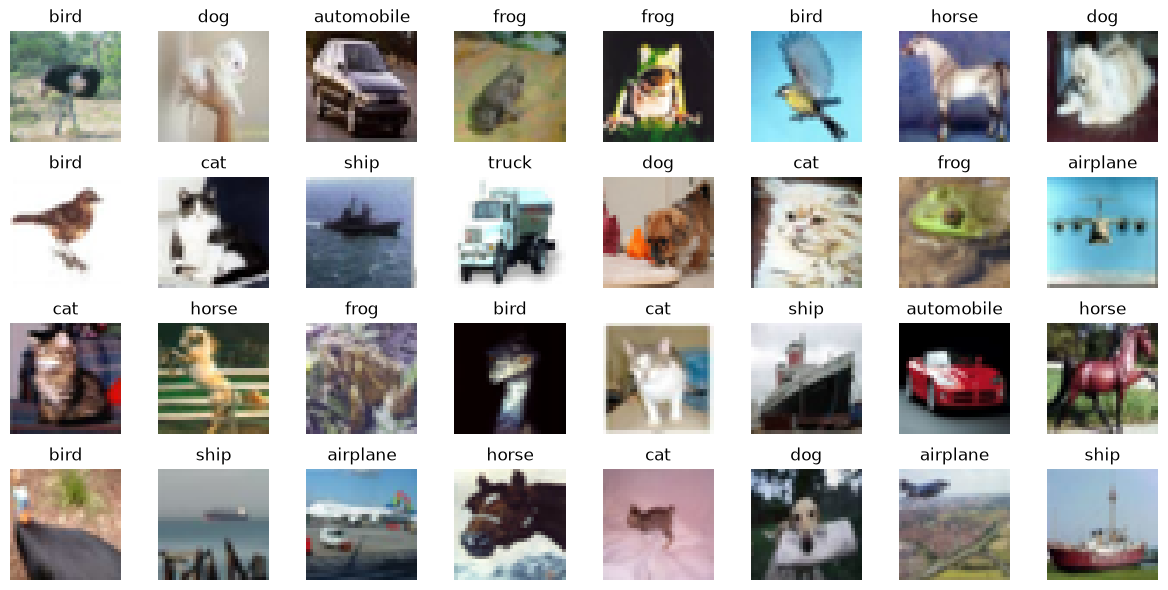

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Select Client 1
trainloader = trainloaders[0]

# Get one batch
batch = next(iter(trainloader))
images, labels = batch["img"], batch["label"]

# Convert from PyTorch format (N, C, H, W)
# to matplotlib format (N, H, W, C)
images = images.permute(0, 2, 3, 1).numpy()

# Denormalize images
images = images / 2 + 0.5
images = np.clip(images, 0, 1)

# Create figure
fig, axs = plt.subplots(4, 8, figsize=(12, 6))

# Plot images
for i, ax in enumerate(axs.flat):
    ax.imshow(images[i])

    label = trainloader.dataset.features["label"].int2str(
        int(labels[i])
    )

    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import sys
import subprocess
from pathlib import Path

# Use Flower from our current venv
FLWR = Path(sys.prefix) / "Scripts" / "flwr.exe"

# Project location
PROJECT = Path.cwd() / "quickstart-pytorch"

# Download only if it doesn't already exist
if not PROJECT.exists():
    subprocess.run(
        [str(FLWR), "new", "@flwrlabs/quickstart-pytorch"],
        cwd=Path.cwd(),
        check=True
    )

print("Flower project:", PROJECT)

Flower project: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\quickstart-pytorch


In [9]:
subprocess.run(
    [
        sys.executable,
        "-m", "pip", "install",
        "--no-deps",
        "-e", str(PROJECT)
    ],
    check=True
)

CompletedProcess(args=['c:\\Users\\rasmu\\OneDrive - BTH Student\\Documents\\PythonProjects\\year4\\AI-Security--DV2607\\Assignment\\.venv311_AI_security\\Scripts\\python.exe', '-m', 'pip', 'install', '--no-deps', '-e', 'c:\\Users\\rasmu\\OneDrive - BTH Student\\Documents\\PythonProjects\\year4\\AI-Security--DV2607\\Assignment\\Part_2-Federated Learning\\quickstart-pytorch'], returncode=0)

In [11]:
# subprocess.run(
#     [
#         str(FLWR),
#         "run", ".",
#         "--federation-config", "num-supernodes=5",
#         "--run-config", "num-server-rounds=2",
#         "--stream"
#     ],
#     cwd=PROJECT,
#     check=True
# )

import subprocess

result = subprocess.run(
    [
        str(FLWR),
        "run", ".",
        "--federation-config", "num-supernodes=5",
        "--run-config", "num-server-rounds=2",
        "--stream"
    ],
    cwd=PROJECT,
    capture_output=True,
    text=True,
    check=False
)

print("Exit code:", result.returncode)
print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)

Exception in thread Thread-5 (_readerthread):
Traceback (most recent call last):
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x90 in pos

Exit code: 1
STDOUT:
 Using SuperLink: local (127.0.0.1:39091)

STDERR:
 None


In [12]:
import os
import sys
import subprocess
from pathlib import Path

# Existing venv
FLWR = Path(sys.prefix) / "Scripts" / "flwr.exe"

# Flower project
PROJECT = Path.cwd() / "quickstart-pytorch"

# Separate Flower runtime
env = os.environ.copy()
env["FLWR_HOME"] = str(Path.home() / ".flwr-dv2607")
env["FLWR_LOCAL_SUPERLINK_HTTP_API_PORT"] = "39092"

# Avoid automatic dependency installation
env["FLWR_DISABLE_RUNTIME_DEPENDENCY_INSTALLATION"] = "1"

print("Flower:", FLWR)
print("Project:", PROJECT)
print("Project found:", (PROJECT / "pyproject.toml").exists())

Flower: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Scripts\flwr.exe
Project: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\quickstart-pytorch
Project found: True


In [13]:
result = subprocess.run(
    [
        str(FLWR),
        "run", ".",
        "--federation-config", "num-supernodes=5",
        "--stream"
    ],
    cwd=PROJECT,
    env=env
)

print("Exit code:", result.returncode)

Exit code: 1


In [14]:
log_path = Path(env["FLWR_HOME"]) / "local-superlink" / "superlink.log"

if log_path.exists():
    print(log_path.read_text(
        encoding="utf-8",
        errors="replace"
    )[-6000:])

In [15]:
from pathlib import Path
import subprocess

result = subprocess.run(
    [
        str(FLWR),
        "run", ".",
        "--federation-config", "num-supernodes=5",
        "--stream"
    ],
    cwd=PROJECT,
    env=env,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print("Exit code:", result.returncode)
print("\nSTDOUT:\n", result.stdout[-4000:])
print("\nSTDERR:\n", result.stderr[-4000:])

# Read the local SuperLink log
log_path = Path(env["FLWR_HOME"]) / "local-superlink" / "superlink.log"

if log_path.exists():
    print("\nSUPERLINK LOG:\n")
    print(log_path.read_text(
        encoding="utf-8",
        errors="replace"
    )[-5000:])
else:
    print("\nNo SuperLink log found at:", log_path)

Exit code: 1

STDOUT:
 Starting local SuperLink on 127.0.0.1:39092...
Using SuperLink: local (127.0.0.1:39092)


STDERR:
 ┌─ Error ─────────────────────────────────────────────────────────────────────┐
│ Internal server error.                                                      │
└─────────────────────────────────────────────────────────────────────────────┘


SUPERLINK LOG:

WARNING flwr 2026-10-25 11:50:25,470 | flower_superlink.py:299 | The `--control-api-address` argument is deprecated. The Control API now operates over HTTP. Use `--host` and `--port` instead.
WARNING flwr 2026-10-25 11:50:25,471 | flower_superlink.py:540 | Option `--insecure` was set. Starting insecure HTTP server with unencrypted communication (TLS disabled). Proceed only if you understand the risks.
WARNING flwr 2026-10-25 11:50:25,471 | flower_superlink.py:402 | SuperNode authentication is disabled. The SuperLink will accept connections from any SuperNode.
INFO flwr 2026-10-25 11:50:25,471 | flower_superlink.p

In [3]:
import os
import sys
import subprocess
from pathlib import Path

PROJECT = Path.cwd() / "quickstart-pytorch"
FLWR = Path(sys.prefix) / "Scripts" / "flwr.exe"

env = os.environ.copy()
env["FLWR_HOME"] = str(Path.home() / ".flwr_dv2607_test")
env["FLWR_LOCAL_SUPERLINK_HTTP_API_PORT"] = "39112"
env["FLWR_DISABLE_RUNTIME_DEPENDENCY_INSTALLATION"] = "1"

result = subprocess.run(
    [
        str(FLWR),
        "run", ".",
        "--federation-config", "num-supernodes=5",
        "--run-config", 'num-server-rounds=2 run-name="test"',
        "--stream"
    ],
    cwd=PROJECT,
    env=env,
    capture_output=True,
    # capture_output=False,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print("Exit code:", result.returncode)
print("STDOUT:", result.stdout[-3000:])
print("STDERR:", result.stderr[-3000:])

log_path = Path(env["FLWR_HOME"]) / "local-superlink" / "superlink.log"

if result.returncode != 0 and log_path.exists():
    print("\nSuperLink log:")
    print(log_path.read_text(
        encoding="utf-8",
        errors="replace"
    )[-5000:])

Exit code: 0
STDOUT: Using SuperLink: local (127.0.0.1:39112)
Successfully started run 16387836694871988001

STDERR: INFO :      Starting logstream for run_id `16387836694871988001`



UsageError: Line magic function `%flwr` not found.
